# Diffusion equation with the forward difference method

In [16]:
import numpy as np
import matplotlib.pyplot as plt

## Discretization

Note:
- Grid: x_i = iΔx, t_n = nΔt, u_i^n = u(x_i, t_n)
- Time: definition of the derivative (Eq. 3.3) with a small Δt instead of the limit gives the forward difference (Eq. 3.4):  
  ∂u/∂t = lim_(Δt -> 0) [u(x, t + Δt) - u(x, t)] / Δt ≈ (u_i^(n+1) - u_i^n) / Δt
- Space: second derivative = forward difference minus backward difference, divided by Δx. Three-point formula (Eq. 3.11), error O(Δx^2):  
  ∂²u/∂x² ≈ [(u_(i+1)^n - u_i^n)/Δx - (u_i^n - u_(i-1)^n)/Δx] / Δx = (u_(i+1)^n - 2u_i^n + u_(i-1)^n) / Δx^2
- Both in the diffusion equation (Eq. 7.90, Euler method):  
  u_i^(n+1) = u_i^n + γ (u_(i+1)^n - 2u_i^n + u_(i-1)^n), with γ = νΔt/Δx^2
- The ends (x = 0 and x = 2.5) have 1 neighbour, so u = 1 there

In [17]:
# One time step of the forward difference method (Eq. 7.90 in the book, with no source term S)
# The book uses n, D, τ, h for u, nu, dt, dx
# u at all grid points at time t_n, gamma = nu*dt/dx^2
# Return u at time t_(n+1)
def step(u, gamma):
    u_new = u.copy()
    #u[2:] is u_(i+1), u[1:-1] is u_i and u[:-2] is u_(i-1), for all inside points at once
    u_new[1:-1] = u[1:-1] + gamma*(u[2:] - 2*u[1:-1] + u[:-2])
    return u_new #the end points are not changed, so they stay 1

## Setup

Note:
- Space: 51 position steps, Δx = 0.05, so x = 0 to 2.5
- Start: u = 3 for 0.5 <= x <= 1, u = 1 everywhere else (u between 1 and 3 m/s)

In [18]:
dx = 0.05 #position step
nx = 51 #number of position steps

# Solve the diffusion equation from t = 0
# nu: diffusion coefficient
# dt: time step
# nt: number of time steps
# Returns the grid x and u after nt time steps
def solve(nu, dt, nt):
    x = np.arange(nx)*dx #x = 0, 0.05,..., 2.5
    u = np.ones(nx) #u = 1 everywhere
    u[(x >= 0.5) & (x <= 1)] = 3 #u = 3 for 0.5 <= x <= 1
    gamma = nu*dt/dx**2 #γ = νΔt/Δx^2
    for n in range(nt):
        u = step(u, gamma)
    return x, u

## ν between 0.1 and 0.9

Note:
- Time: 151 time steps, Δt = 5*10^-4, so t = 0 to 0.0755
- ν = 0.1, 0.3, 0.5, 0.7, 0.9

ν = 0.1: γ = 0.02, u between 1.00 and 2.95
ν = 0.3: γ = 0.06, u between 1.00 and 2.61
ν = 0.5: γ = 0.10, u between 1.00 and 2.37
ν = 0.7: γ = 0.14, u between 1.00 and 2.21
ν = 0.9: γ = 0.18, u between 1.00 and 2.09


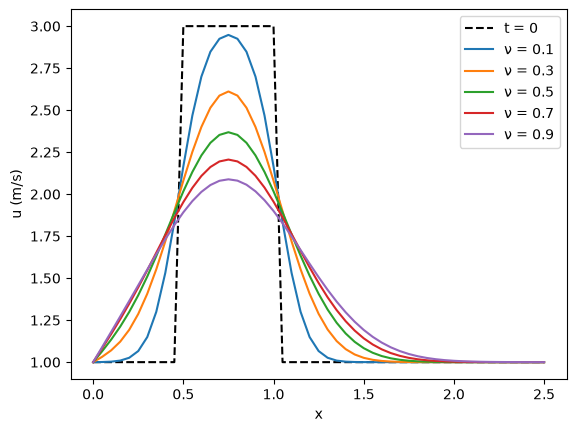

In [19]:
dt = 5e-4 #time step
nt = 151 #number of time steps
nu_values = [0.1, 0.3, 0.5, 0.7, 0.9] #diffusion coefficients

# Plot
fig, ax = plt.subplots()
x, u_start = solve(0.1, dt, 0) #0 time steps, so this is the starting condition
ax.plot(x, u_start, 'k--', label='t = 0')
for nu in nu_values:
    x, u = solve(nu, dt, nt)
    ax.plot(x, u, label=f'ν = {nu}')
    print(f"ν = {nu}: γ = {nu*dt/dx**2:.2f}, u between {u.min():.2f} and {u.max():.2f}")
ax.set_xlabel('x'); ax.set_ylabel('u (m/s)'); ax.legend()
plt.show()

Note:
- γ = νΔt/Δx^2 = ν*(5*10^-4)/0.05^2 = 0.2ν so γ ranges from 0.02 (ν = 0.1) to 0.18 (ν = 0.9)
- Larger ν diffuses faster. Therefore, the peak is lower and wider.
- u stays between 1 and 3 m/s for every ν

## Argument not to use this approach

ν = 0.1: largest |u| = 2.04
ν = 0.3: largest |u| = 6.88e+20


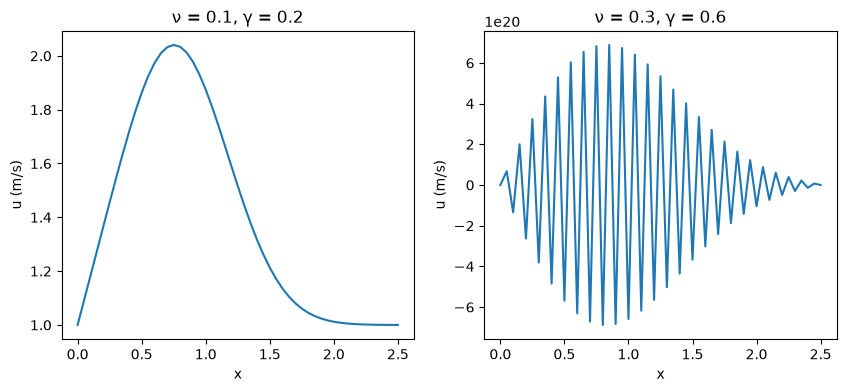

In [20]:
dt_big = 5e-3 #10 times larger time step
nu_compare = [0.1, 0.3] #the two ν from the hint

# Plot
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for k, nu in enumerate(nu_compare): #k = 0 left plot, k = 1 right plot
    x, u = solve(nu, dt_big, nt)
    ax[k].plot(x, u)
    ax[k].set_title(f'ν = {nu}, γ = {nu*dt_big/dx**2:.1f}')
    ax[k].set_xlabel('x'); ax[k].set_ylabel('u (m/s)')
    print(f"ν = {nu}: largest |u| = {np.abs(u).max():.3g}")
plt.show()

Note:
- ν = 0.1 is still smooth, ν = 0.3 blows up
- The method is unstable for γ > 1/2 (section 7.7), so I need Δt <= Δx^2/(2ν)
- ν = 0.1: Δt <= 0.05^2/(2*0.1) = 1.25*10^-2, so Δt = 5·10^-3 is fine
- ν = 0.3: Δt <= 0.05^2/(2*0.3) = 4.2*10^-3, so Δt = 5*10^-3 is too large and u blows up
- Therefore, the time step is limited by stability, not by accuracy. Larger ν needs smaller Δt. If Δx is 2 times smaller, Δt must be 4 times smaller so the method needs very many time steps, which is my argument why not to use it.